# October 2026: Three Datasets, One Record
### Did October 2026 set the global temperature record by the same margin in every dataset?

Copernicus reports October 2026 as the warmest October on record, and a strong El Niño is under way. This notebook asks how far ahead of the old record each dataset puts it, how that margin compares with the margins of other monthly records, and how much of the warmth the trend and El Niño together would predict. The data are NASA's GISTEMP monthly global means, NOAA's October global series, ERA5 daily global means from Copernicus and ECMWF, and NOAA's Oceanic Niño Index.

## 1. Setup

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
CHARTS = ROOT / "charts"
PROCESSED.mkdir(exist_ok=True)
CHARTS.mkdir(exist_ok=True)

YEAR = 2026
BASE = (1991, 2020)       # every series is shown relative to this period
MODEL_FIRST = 1979        # the first year of ERA5 satellite-era coverage used for the model
SLATE, ROSE, SEPIA, INK, SOFT, RULE = "#3f6c96", "#c06a85", "#a8793a", "#1c1e21", "#8b8e93", "#e3e4e1"
plt.rcParams["font.family"] = ["Helvetica Neue", "Helvetica", "DejaVu Sans"]
results = {}

## 2. Load the data

In [2]:
meta = json.loads((RAW / "download.json").read_text())
print("Downloaded:", meta["downloaded"])

MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

# NASA GISTEMP: one row per year, one column per month, in degrees C relative to 1951-1980
g = pd.read_csv(RAW / "gistemp_global_monthly.csv", skiprows=1, na_values="***").set_index("Year")
gistemp = (g[MONTHS].stack().rename("value").reset_index()
           .rename(columns={"Year": "year", "level_1": "mon"}))
gistemp["month"] = gistemp["mon"].map({m: i + 1 for i, m in enumerate(MONTHS)})
gistemp = gistemp[["year", "month", "value"]]

# NOAA: October only, relative to 1901-2000
noaa = (pd.read_csv(RAW / "noaaglobaltemp_october.csv", comment="#")
        .rename(columns={"Year": "year", "Departure from Average": "value"}))
noaa["month"] = 10

# ERA5 daily global mean, with daily anomalies against the 1991-2020 climatology
e = pd.read_csv(RAW / "era5_daily_global_2t.csv", comment="#", parse_dates=["date"])
e["year"], e["month"] = e["date"].dt.year, e["date"].dt.month
era5 = (e.groupby(["year", "month"]).agg(value=("ano_91-20", "mean"), days=("date", "count"),
                                           final=("status", lambda s: (s == "FINAL").all()))
        .reset_index())
era5["days_in_month"] = pd.to_datetime(dict(year=era5.year, month=era5.month, day=1)).dt.days_in_month
era5_all = era5.copy()
era5 = era5[era5.days == era5.days_in_month][["year", "month", "value"]]

# NOAA Oceanic Niño Index, three-month seasons
oni = pd.read_csv(RAW / "oni.ascii.txt", sep=r"\s+")
print("GISTEMP:", gistemp.year.min(), "to", gistemp.year.max(), "| NOAA:", noaa.year.min(), "to", noaa.year.max(),
      "| ERA5:", era5.year.min(), "to", era5.year.max())

Downloaded: 2026-11-23
GISTEMP: 1880 to 2026 | NOAA: 1850 to 2026 | ERA5: 1940 to 2026


GISTEMP and NOAA each publish a monthly value for the whole globe, and ERA5 comes as one value per day, so I average each month's days. I use a month only when every day is present.

## 3. Data checks

In [3]:
checks = {}
oct_g = gistemp[gistemp.month == 10].set_index("year").value
oct_n = noaa.set_index("year").value
oct_e = era5[era5.month == 10].set_index("year").value
for name, s, first in [("GISTEMP", oct_g, 1880), ("NOAA", oct_n, 1850), ("ERA5", oct_e, 1940)]:
    assert s.index.min() == first and s.index.max() == YEAR, name
    assert s.index.is_unique and s.notna().all(), name
    assert s.index.equals(pd.Index(range(first, YEAR + 1))), f"{name} has a gap"
    print(f"{name}: {len(s)} Octobers, {first} to {YEAR}, no gaps")

oct26 = era5_all[(era5_all.year == YEAR) & (era5_all.month == 10)].iloc[0]
assert oct26.days == 31 and bool(oct26.final), "ERA5 October 2026 is incomplete or preliminary"
print("ERA5 October 2026: 31 of 31 days, all FINAL")

incomplete = era5_all[era5_all.days != era5_all.days_in_month]
print("ERA5 months left out as incomplete:", [f"{int(r.year)}-{int(r.month):02d}" for r in incomplete.itertuples()])
assert "ASO" in set(oni.SEAS) and ((oni.SEAS == "ASO") & (oni.YR == YEAR)).any()
print("Latest ONI season in the file:", oni.iloc[-1].SEAS, int(oni.iloc[-1].YR))

GISTEMP: 147 Octobers, 1880 to 2026, no gaps
NOAA: 177 Octobers, 1850 to 2026, no gaps
ERA5: 87 Octobers, 1940 to 2026, no gaps
ERA5 October 2026: 31 of 31 days, all FINAL
ERA5 months left out as incomplete: ['2026-11']
Latest ONI season in the file: ASO 2026


Every October series is complete, and ERA5's October 2026 is final in all 31 days, so none of the values I compare is preliminary. The only incomplete ERA5 month is the one still in progress.

## 4. October across the three datasets

In [4]:
def rebase(s):
    """Express a series relative to its own 1991-2020 average."""
    return s - s.loc[BASE[0]:BASE[1]].mean()

octo = pd.DataFrame({"NASA GISTEMP": rebase(oct_g), "NOAA GlobalTemp": rebase(oct_n), "ERA5": rebase(oct_e)})
rows = []
for name in octo:
    s = octo[name].dropna()
    prior = s[s.index < YEAR]
    best = prior.max()
    tied = [int(y) for y in prior.index[np.isclose(prior, best)]]
    rows.append({"dataset": name, "record_year": int(s.idxmax()), "value_2026": round(float(s[YEAR]), 2),
                 "previous_record_years": tied, "previous_record": round(float(best), 2),
                 "margin": round(float(s[YEAR] - best), 2), "first_year": int(s.index.min())})
table = pd.DataFrame(rows)
table

,dataset,record_year,value_2026,previous_record_years,previous_record,margin,first_year
0,NASA GISTEMP,2026,0.94,"[2023, 2024]",0.73,0.21,1880
1,NOAA GlobalTemp,2026,0.82,[2023],0.75,0.08,1850
2,ERA5,2026,0.90,[2023],0.85,0.05,1940


In [5]:
raw_margin = {"NASA GISTEMP": oct_g[YEAR] - oct_g[oct_g.index < YEAR].max(),
              "NOAA GlobalTemp": oct_n[YEAR] - oct_n[oct_n.index < YEAR].max(),
              "ERA5": oct_e[YEAR] - oct_e[oct_e.index < YEAR].max()}
for name, m in raw_margin.items():
    print(f"{name}: ahead of the old record by {m:.3f} °C")
assert all(table.record_year == YEAR)
# Re-basing moves every year by the same amount, so it can't change a margin
for r in table.itertuples():
    assert abs(r.margin - raw_margin[r.dataset]) < 0.006, r.dataset

top = {name: octo[name].dropna().nlargest(5, keep="all") for name in octo}
results["october"] = table.to_dict("records")
results["october_top5"] = {n: {int(y): round(float(v), 2) for y, v in s.items()} for n, s in top.items()}
results["era5_october_2026_vs_1991_2020_published_basis"] = round(float(oct_e[YEAR]), 2)
results["era5_october_2023"] = round(float(oct_e[2023]), 2)
results["era5_october_2024"] = round(float(oct_e[2024]), 2)
results["gistemp_october_ties"] = [int(y) for y in oct_g.index[oct_g == oct_g[[2023, 2024]].max()] if y < YEAR]
results["gistemp_2026_value_raw"] = round(float(oct_g[YEAR]), 2)
results["noaa_2026_value_raw"] = round(float(oct_n[YEAR]), 2)

NASA GISTEMP: ahead of the old record by 0.210 °C
NOAA GlobalTemp: ahead of the old record by 0.080 °C
ERA5: ahead of the old record by 0.054 °C


All three put October 2026 first, so the ranking agrees. The margin doesn't: NASA has it 0.21°C ahead of the old record, NOAA 0.08°C and ERA5 0.05°C. In NASA's series the two previous best Octobers, 2023 and 2024, are tied at 1.34 on the raw scale, so the old record is shared by two years. In ERA5 and NOAA, 2023 is second.

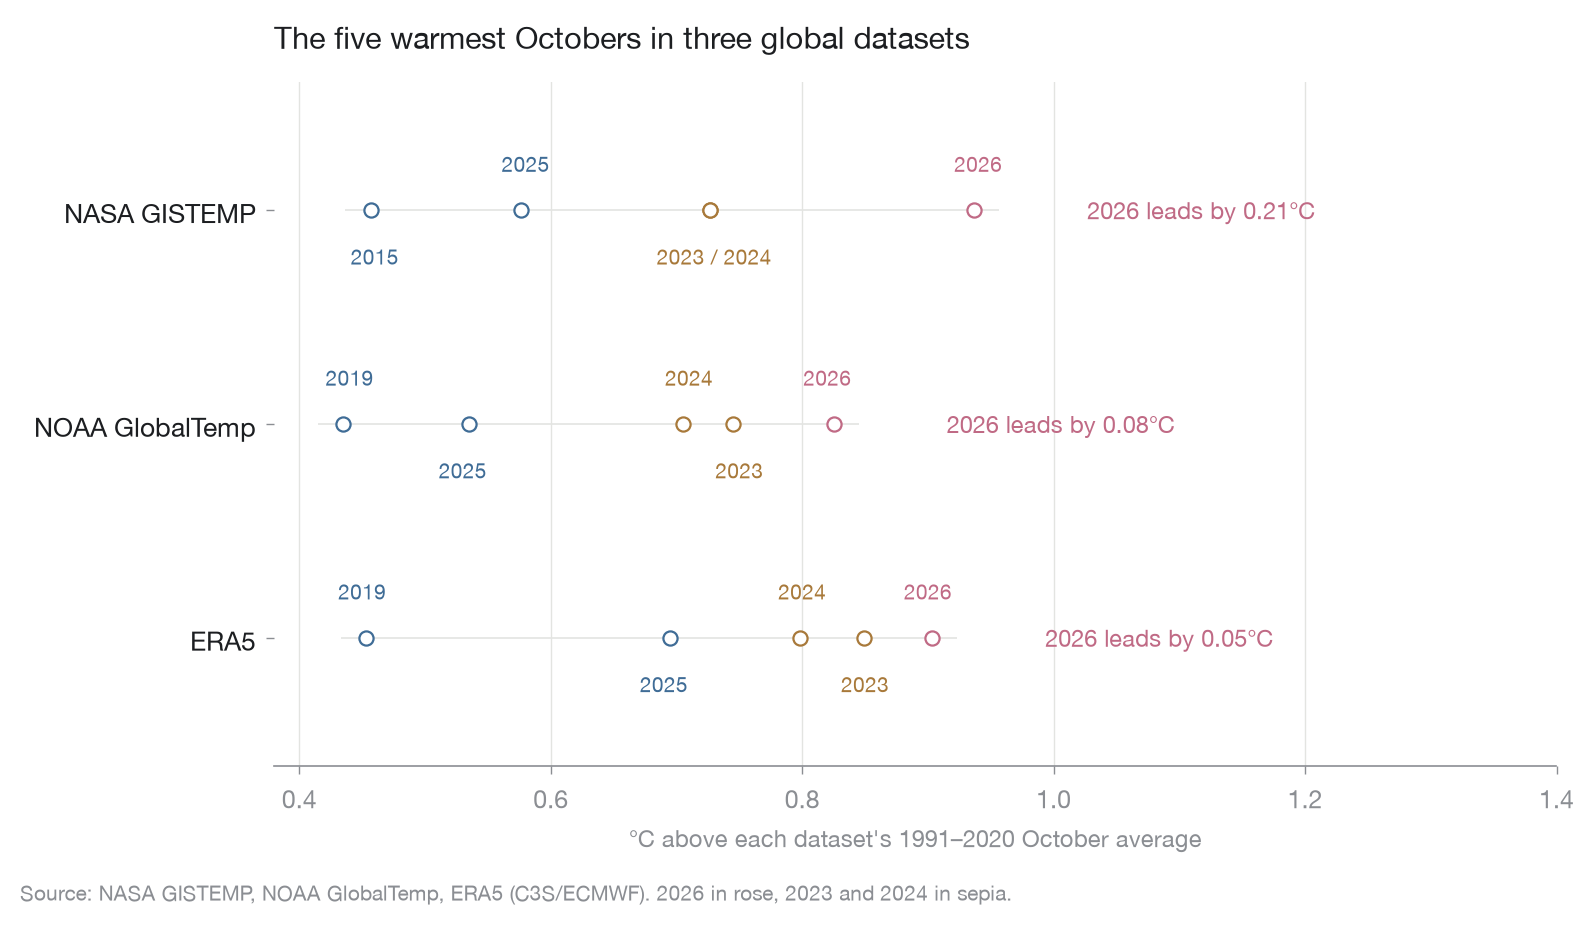

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.6), dpi=200)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(SOFT); ax.spines["bottom"].set_linewidth(0.6)
ax.tick_params(colors=SOFT, labelsize=9, width=0.5, length=3)
ax.grid(axis="x", color=RULE, linewidth=0.5); ax.set_axisbelow(True)
order = ["NASA GISTEMP", "NOAA GlobalTemp", "ERA5"]
for i, name in enumerate(order):
    y = len(order) - 1 - i
    s = top[name]
    ax.hlines(y, s.min() - 0.02, s.max() + 0.02, color=RULE, linewidth=0.6, zorder=1)
    for yr, v in s.items():
        c = ROSE if yr == YEAR else SEPIA if yr in (2023, 2024) else SLATE
        ax.scatter(v, y, s=26, facecolor="white", edgecolor=c, linewidth=0.8, zorder=3)
    labeled = {}
    for yr, v in s.items():
        labeled.setdefault(round(v, 2), []).append(int(yr))
    for k, (v, yrs) in enumerate(sorted(labeled.items(), reverse=True)):
        c = ROSE if YEAR in yrs else SEPIA if any(t in (2023, 2024) for t in yrs) else SLATE
        ax.text(v, y + (0.16 if k % 2 == 0 else -0.16), " / ".join(str(t) for t in yrs), ha="center",
                va="bottom" if k % 2 == 0 else "top", fontsize=7.5, color=c)
    m = table.set_index("dataset").loc[name, "margin"]
    ax.text(s.max() + 0.09, y, f"2026 leads by {m:.2f}°C", va="center", fontsize=8.5, color=ROSE)
ax.set_yticks(range(len(order)), order[::-1] and [o for o in reversed(order)], color=INK, fontsize=9.5)
ax.set_xlim(0.38, 1.4); ax.set_ylim(-0.6, len(order) - 0.4)
ax.set_xlabel("°C above each dataset's 1991–2020 October average", fontsize=8.5, color=SOFT)
ax.set_title("The five warmest Octobers in three global datasets", loc="left", fontsize=11, color=INK, pad=12)
fig.text(0.01, 0.01, "Source: NASA GISTEMP, NOAA GlobalTemp, ERA5 (C3S/ECMWF). 2026 in rose, 2023 and 2024 in sepia.",
         fontsize=7.5, color=SOFT)
fig.tight_layout(rect=(0, 0.03, 1, 1))
for ext in ("png", "svg"):
    fig.savefig(CHARTS / f"1-october-three-datasets.{ext}", facecolor="white")
plt.show()

## 5. How big is a margin of 0.05 to 0.21°C?

A record is only a number until I know what usually happens when one is set. So I took every calendar month since 1950 in which a dataset set a new record for that month, and measured how far it beat the previous best. NOAA's file I downloaded holds October only, so this step uses NASA and ERA5.

In [7]:
def record_margins(df, first_year=1950):
    out = []
    for month, grp in df.groupby("month"):
        grp = grp.sort_values("year")
        best = None
        for r in grp.itertuples():
            if best is not None and r.value > best and r.year >= first_year:
                out.append({"year": int(r.year), "month": int(month), "margin": float(r.value - best)})
            best = r.value if best is None else max(best, r.value)
    return pd.DataFrame(out)

rm = {"NASA GISTEMP": record_margins(gistemp[["year", "month", "value"]]),
      "ERA5": record_margins(era5)}
summary = {}
for name, d in rm.items():
    d = d.sort_values("margin", ascending=False).reset_index(drop=True)
    oct26 = d[(d.year == YEAR) & (d.month == 10)].iloc[0]
    rank = int((d.margin > oct26.margin + 1e-9).sum() + 1)
    summary[name] = {"records": int(len(d)), "median_margin": round(float(d.margin.median()), 2),
                     "oct2026_margin": round(float(oct26.margin), 2), "oct2026_rank": rank,
                     "largest": [{"year": int(r.year), "month": int(r.month), "margin": round(float(r.margin), 2)}
                                 for r in d.head(3).itertuples()]}
    print(name, summary[name])
results["record_margins_since_1950"] = summary

NASA GISTEMP

 {'records': 133, 'median_margin': 0.07, 'oct2026_margin': 0.21, 'oct2026_rank': 16, 'largest': [{'year': 2023, 'month': 9, 'margin': 0.52}, {'year': 2016, 'month': 2, 'margin': 0.45}, {'year': 2016, 'month': 3, 'margin': 0.4}]}
ERA5 {'records': 152, 'median_margin': 0.07, 'oct2026_margin': 0.05, 'oct2026_rank': 89, 'largest': [{'year': 2023, 'month': 9, 'margin': 0.5}, {'year': 2016, 'month': 2, 'margin': 0.46}, {'year': 2023, 'month': 10, 'margin': 0.4}]}


In NASA's data the October margin ranks 16th of 133 record months since 1950, and in ERA5 it ranks 89th of 152. The median record month beat its predecessor by 0.07°C in both series, so ERA5's margin of 0.05°C for October 2026 is smaller than the typical record, and NASA's 0.21°C is about three times the typical one. The largest margin in both is September 2023, at 0.52°C in NASA's data and 0.50°C in ERA5's.

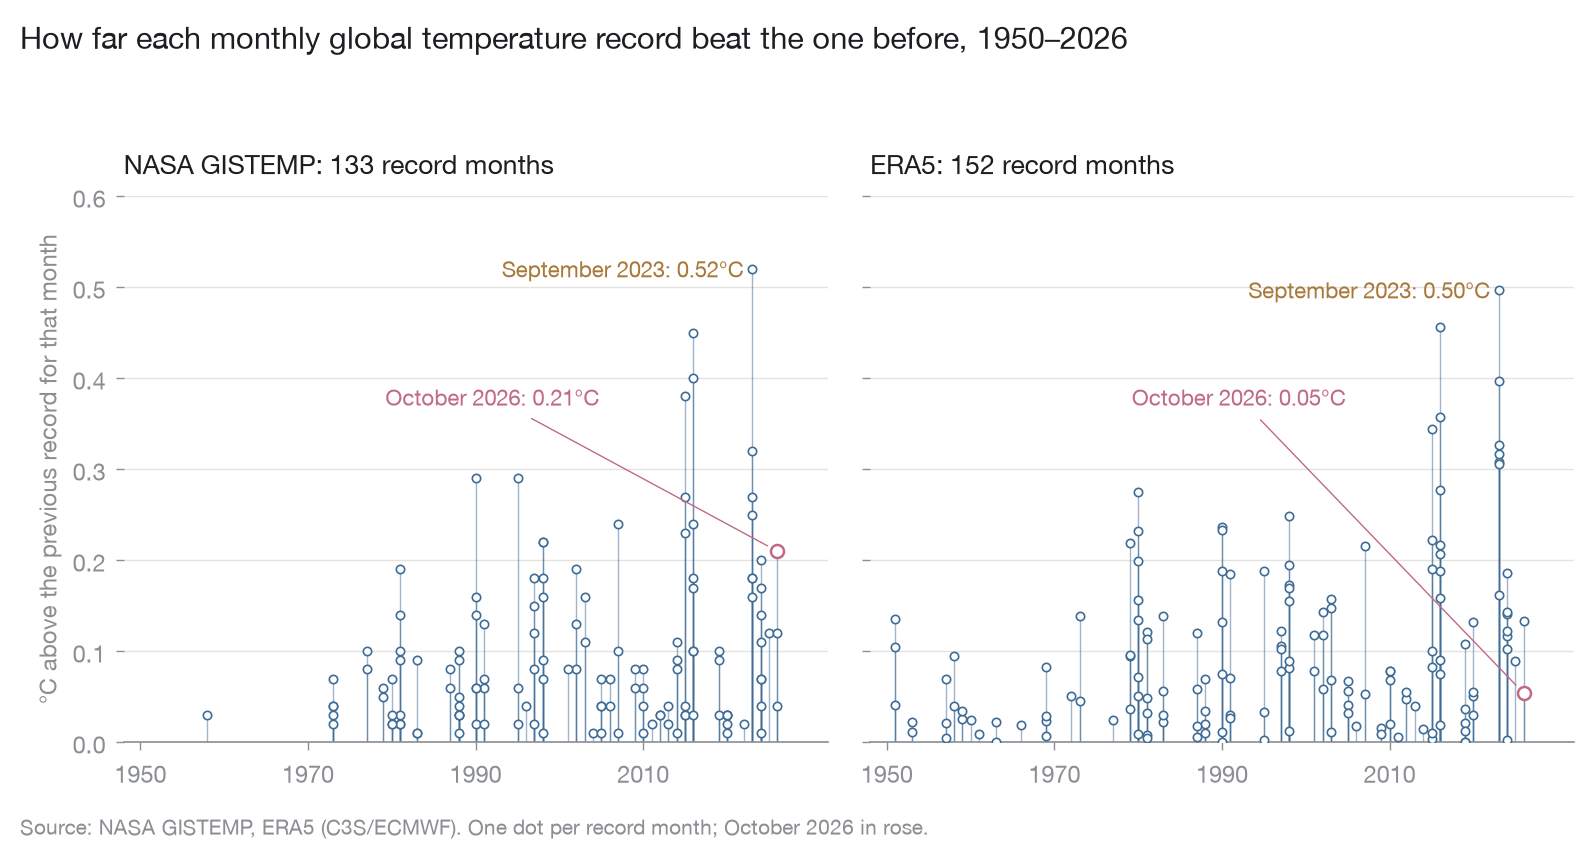

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4.2), dpi=200, sharey=True)
for ax, (name, d) in zip(axes, rm.items()):
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(SOFT); ax.spines["bottom"].set_linewidth(0.6)
    ax.tick_params(colors=SOFT, labelsize=8.5, width=0.5, length=3)
    ax.grid(axis="y", color=RULE, linewidth=0.5); ax.set_axisbelow(True)
    ax.vlines(d.year, 0, d.margin, color=SLATE, linewidth=0.5, alpha=0.5)
    ax.scatter(d.year, d.margin, s=9, facecolor="white", edgecolor=SLATE, linewidth=0.6, zorder=3)
    o = d[(d.year == YEAR) & (d.month == 10)]
    ax.scatter(o.year, o.margin, s=22, facecolor="white", edgecolor=ROSE, linewidth=0.9, zorder=4)
    om = float(o.margin.iloc[0])
    ax.annotate(f"October 2026: {om:.2f}°C", xy=(YEAR, om), xytext=(1992, 0.37), color=ROSE, fontsize=8, ha="center",
                arrowprops=dict(arrowstyle="-", color=ROSE, linewidth=0.5, shrinkA=2, shrinkB=4))
    sep = d[(d.year == 2023) & (d.month == 9)]
    ax.text(2023 - 1, float(sep.margin.iloc[0]), f"September 2023: {float(sep.margin.iloc[0]):.2f}°C",
            ha="right", va="center", color=SEPIA, fontsize=8)
    ax.set_title(f"{name}: {len(d)} record months", loc="left", fontsize=9.5, color=INK, pad=8)
    ax.set_xlim(1948, 2032); ax.set_xticks(range(1950, 2030, 20)); ax.set_ylim(0, 0.6)
axes[0].set_ylabel("°C above the previous record for that month", fontsize=8.5, color=SOFT)
fig.suptitle("How far each monthly global temperature record beat the one before, 1950–2026", x=0.01, ha="left",
             fontsize=11, color=INK)
fig.text(0.01, 0.01, "Source: NASA GISTEMP, ERA5 (C3S/ECMWF). One dot per record month; October 2026 in rose.",
         fontsize=7.5, color=SOFT)
fig.tight_layout(rect=(0, 0.03, 1, 0.94))
for ext in ("png", "svg"):
    fig.savefig(CHARTS / f"2-record-margins.{ext}", facecolor="white")
plt.show()

## 6. How much would the trend and El Niño predict?

El Niño warms the global average, usually with a lag of a few months, and October 2026 came with a strong one: the Oceanic Niño Index for August to October was 2.46. So I fit each dataset's October values from 1979 to 2025 against the year and that index, and asked what the fit would have predicted for 2026.

In [9]:
aso = oni[oni.SEAS == "ASO"].set_index("YR").ANOM
jja = oni[oni.SEAS == "JJA"].set_index("YR").ANOM
print("ASO 2026:", aso[YEAR], "| ASO 2023:", aso[2023], "| JJA 2026:", jja[YEAR])

def fit(series, index, first=MODEL_FIRST):
    d = pd.DataFrame({"t": series, "oni": index}).dropna()
    d = d[(d.index >= first)]
    tr = d[d.index < YEAR]
    X = np.c_[np.ones(len(tr)), tr.index - 2000, tr.oni]
    b, *_ = np.linalg.lstsq(X, tr.t.to_numpy(), rcond=None)
    sd = float((tr.t - X @ b).std(ddof=3))
    pred = float(b @ [1, YEAR - 2000, d.loc[YEAR, "oni"]])
    return {"n": int(len(tr)), "trend_per_decade": round(float(b[1] * 10), 2), "oni_coefficient": round(float(b[2]), 2),
            "predicted_2026": round(pred, 2), "actual_2026": round(float(d.loc[YEAR, "t"]), 2),
            "gap": round(float(d.loc[YEAR, "t"]) - pred, 2), "scatter_sd": round(sd, 2),
            "gap_in_sd": round((float(d.loc[YEAR, "t"]) - pred) / sd, 1)}

model = {}
for name, s in [("NASA GISTEMP", oct_g), ("NOAA GlobalTemp", oct_n), ("ERA5", oct_e)]:
    model[name] = {"ASO": fit(s, aso), "JJA": fit(s, jja)}
    print(name, model[name]["ASO"])
results["el_nino_model"] = model
results["oni_aso_2026"], results["oni_aso_2023"], results["oni_jja_2026"] = float(aso[YEAR]), float(aso[2023]), float(jja[YEAR])

ASO 2026: 2.46 | ASO 2023: 1.5 | JJA 2026: 1.8
NASA GISTEMP {'n': 47, 'trend_per_decade': 0.24, 'oni_coefficient': 0.07, 'predicted_2026': 1.31, 'actual_2026': 1.55, 'gap': 0.24, 'scatter_sd': 0.11, 'gap_in_sd': 2.1}
NOAA GlobalTemp {'n': 47, 'trend_per_decade': 0.23, 'oni_coefficient': 0.07, 'predicted_2026': 1.3, 'actual_2026': 1.43, 'gap': 0.13, 'scatter_sd': 0.11, 'gap_in_sd': 1.2}
ERA5 {'n': 47, 'trend_per_decade': 0.27, 'oni_coefficient': 0.07, 'predicted_2026': 0.76, 'actual_2026': 0.9, 'gap': 0.14, 'scatter_sd': 0.13, 'gap_in_sd': 1.1}


The fit predicts about 1.31°C for NASA, 1.30°C for NOAA and 0.76°C for ERA5, each a little cooler than what happened. In ERA5 and NOAA the shortfall is about 0.14°C, roughly one standard deviation of the usual scatter around the fit, and in NASA it's 0.24°C, about two. So a trend plus a strong El Niño covers most of the warmth, and the leftover is the size of an ordinary year's noise in two datasets and a little more in one.

In [10]:
print("Using the index from three months earlier (June to August):")
for name in model:
    r = model[name]["JJA"]
    print(f"  {name}: predicted {r['predicted_2026']}, actual {r['actual_2026']}, gap {r['gap']} ({r['gap_in_sd']} sd)")

Using the index from three months earlier (June to August):
  NASA GISTEMP: predicted 1.29, actual 1.55, gap 0.26 (2.3 sd)
  NOAA GlobalTemp: predicted 1.28, actual 1.43, gap 0.15 (1.4 sd)
  ERA5: predicted 0.75, actual 0.9, gap 0.15 (1.1 sd)


## 7. Recompute the main figures with independent code

Last, I rebuild the October values, the margins and the record-margin ranks with plain Python and the csv module, without any of the pandas steps above, and stop if a single figure differs.

In [11]:
import csv

def gistemp_october():
    rows = list(csv.reader(open(RAW / "gistemp_global_monthly.csv")))[2:]
    return {int(r[0]): float(r[10]) for r in rows if r[0].isdigit() and r[10] != "***"}

def noaa_october():
    return {int(r[0]): float(r[1]) for r in csv.reader(open(RAW / "noaaglobaltemp_october.csv"))
            if r and r[0].isdigit()}

def era5_monthly():
    sums, counts = {}, {}
    for line in open(RAW / "era5_daily_global_2t.csv"):
        if line.startswith("#") or line.startswith("date"):
            continue
        d, _, _, ano, _ = line.strip().split(",")
        key = (int(d[:4]), int(d[5:7]))
        sums[key] = sums.get(key, 0.0) + float(ano)
        counts[key] = counts.get(key, 0) + 1
    import calendar
    return {k: sums[k] / counts[k] for k in sums if counts[k] == calendar.monthrange(*k)[1]}

g_o, n_o, e_m = gistemp_october(), noaa_october(), era5_monthly()
e_o = {y: v for (y, m), v in e_m.items() if m == 10}

def margin(d):
    return d[YEAR] - max(v for y, v in d.items() if y < YEAR)

for name, d in [("NASA GISTEMP", g_o), ("NOAA GlobalTemp", n_o), ("ERA5", e_o)]:
    mine = round(margin(d), 2)
    theirs = float(table.set_index("dataset").loc[name, "margin"])
    assert abs(mine - theirs) < 0.0051, (name, mine, theirs)
    assert max(d, key=d.get) == YEAR, name
    print(f"{name}: record year {YEAR}, margin {mine:.2f} (matches)")

def ranks(monthly):
    best, margins = {}, []
    for (y, m) in sorted(monthly):
        v = monthly[(y, m)]
        if m in best and v > best[m] and y >= 1950:
            margins.append((v - best[m], y, m))
        best[m] = max(best.get(m, v), v)
    margins.sort(reverse=True)
    pos = [i for i, (_, y, m) in enumerate(margins) if (y, m) == (YEAR, 10)][0] + 1
    return len(margins), pos

g_m = {}
for r in list(csv.reader(open(RAW / "gistemp_global_monthly.csv")))[2:]:
    if r[0].isdigit():
        for m in range(1, 13):
            if r[m] != "***":
                g_m[(int(r[0]), m)] = float(r[m])
for name, monthly in [("NASA GISTEMP", g_m), ("ERA5", e_m)]:
    n_rec, pos = ranks(monthly)
    s = summary[name]
    assert n_rec == s["records"] and pos == s["oct2026_rank"], (name, n_rec, pos)
    print(f"{name}: {n_rec} record months, October 2026 ranks {pos} (matches)")
print("All independent figures match.")

NASA GISTEMP: record year 2026, margin 0.21 (matches)


NOAA GlobalTemp: record year 2026, margin 0.08 (matches)
ERA5: record year 2026, margin 0.05 (matches)


NASA GISTEMP: 133 record months, October 2026 ranks 16 (matches)
ERA5: 152 record months, October 2026 ranks 89 (matches)
All independent figures match.


## Conclusions and limitations

October 2026 is the warmest October on record in NASA's, NOAA's and ERA5's data, so the ranking doesn't depend on which dataset you pick. The size of the lead does: 0.21°C in NASA's series, 0.08°C in NOAA's and 0.05°C in ERA5's. Against all the other monthly records since 1950, the NASA margin ranks 16th of 133 and the ERA5 margin 89th of 152. A fit of the October values on the year and the Oceanic Niño Index puts 2026 about 0.13 to 0.24°C short of what happened, which is one to two standard deviations of the usual scatter.

The limits matter. The three groups build their global averages differently, from different measurements, ocean data and ways of filling gaps, and I haven't looked into which of those choices produces the different margins. HadCRUT5, which I'd want as a fourth dataset, only runs through July 2026 in the file I could download, and Berkeley Earth's public file stops in 2024. The NOAA file holds October alone, so the record-margin comparison uses two datasets. The El Niño fit is a two-variable regression on 47 Octobers, it treats the relationship as linear, and it uses the index for the same season rather than a longer lag, though a lag of three months gives a similar picture. Also, one October is a single data point: a larger or smaller margin in a single month says little about the long-term rate of warming.

In [12]:
(PROCESSED / "results.json").write_text(json.dumps(results, indent=2))
octo.round(3).to_csv(PROCESSED / "october_rebased_1991_2020.csv")
for name, d in rm.items():
    d.round(3).to_csv(PROCESSED / f"record_margins_{name.split()[-1].lower()}.csv", index=False)
print("saved", sorted(p.name for p in PROCESSED.iterdir()))

saved ['october_rebased_1991_2020.csv', 'record_margins_era5.csv', 'record_margins_gistemp.csv', 'results.json']
